# Customer Churn — Dataset Exploration

## Objective
Explore the customer churn dataset to understand its
structure, data quality, feature distributions and
potential limitations before developing a baseline.

## Dataset
customer-churn-training.csv

## Target Variable
churned (1 = churned, 0 = not churned)

In [2]:
%pip install pandas numpy matplotlib seaborn scikit-learn jupyter ipykernel

  Using cached numpy-2.5.5-cp313-cp313-macosx_14_0_arm64.whl.metadata (6.6 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 17.2 MB/s  0:00:00m0:00:010:01
Using cached numpy-2.5.5-cp313-cp313-macosx_14_0_arm64.whl (5.5 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 10.2 MB/s  0:00:00eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.3/8.3 MB 17.3 MB/s  0:00:00 eta 0:00:01
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 19.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 12.0 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20.5/20.5 MB 13.0 MB/s  0:00:01 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16/16 [seaborn]5/16 [seaborn]ib]n]
Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

All libraries imported successfully!
Pandas version: 3.1.1
NumPy version: 2.5.5


In [4]:
df = pd.read_csv("../data/customer-churn-training.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [5]:
print("First five records:")
display(df.head())

print("Dataset dimensions:")
print(df.shape)

print("Column names:")
print(df.columns.tolist())

print("Data types:")
print(df.dtypes)

First five records:


,customer_id,tenure_months,support_tickets,monthly_spend_inr,last_login_days,plan_type,churned
0,C001,2,4,499,21,Basic,1
1,C002,18,1,1299,2,Pro,0
2,C003,6,3,799,14,Basic,1
3,C004,30,0,1499,1,Pro,0
4,C005,11,2,999,5,Standard,0


Dataset dimensions:
(12, 7)
Column names:
['customer_id', 'tenure_months', 'support_tickets', 'monthly_spend_inr', 'last_login_days', 'plan_type', 'churned']
Data types:
customer_id            str
tenure_months        int64
support_tickets      int64
monthly_spend_inr    int64
last_login_days      int64
plan_type              str
churned              int64
dtype: object


In [6]:
print("Missing values:")
display(df.isnull().sum())

print("Duplicate rows:")
print(df.duplicated().sum())

print("Unique customer IDs:")
print(df["customer_id"].nunique())

print("Statistical summary:")
display(df.describe())

Missing values:


customer_id          0
tenure_months        0
support_tickets      0
monthly_spend_inr    0
last_login_days      0
plan_type            0
churned              0
dtype: int64

Duplicate rows:
0
Unique customer IDs:
12
Statistical summary:


,tenure_months,support_tickets,monthly_spend_inr,last_login_days,churned
count,12.000000,12.000000,12.000000,12.000000,12.000000
mean,12.166667,2.250000,915.666667,10.000000,0.416667
std,9.242524,1.602555,332.574895,9.095453,0.514929
min,1.000000,0.000000,499.000000,1.000000,0.000000
25%,5.500000,1.000000,724.000000,2.750000,0.000000
50%,9.500000,2.000000,899.000000,7.000000,0.000000
75%,18.500000,3.250000,1074.000000,14.750000,1.000000
max,30.000000,5.000000,1499.000000,30.000000,1.000000


In [7]:
print("Churn distribution:")
display(df["churned"].value_counts())

print("\nChurn percentage:")
display(df["churned"].value_counts(normalize=True) * 100)

Churn distribution:


churned
0    7
1    5
Name: count, dtype: int64


Churn percentage:


churned
0    58.333333
1    41.666667
Name: proportion, dtype: float64

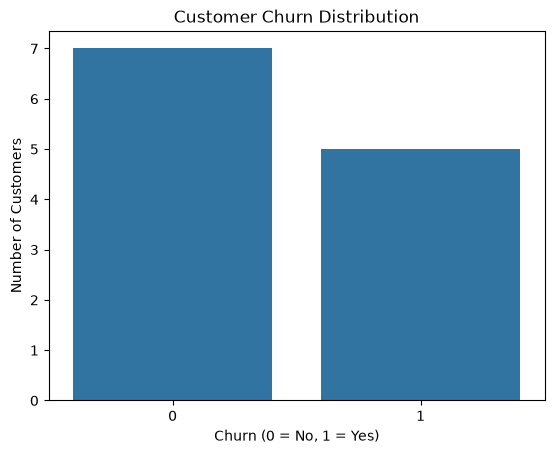

In [8]:
sns.countplot(data=df, x="churned")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")

plt.show()

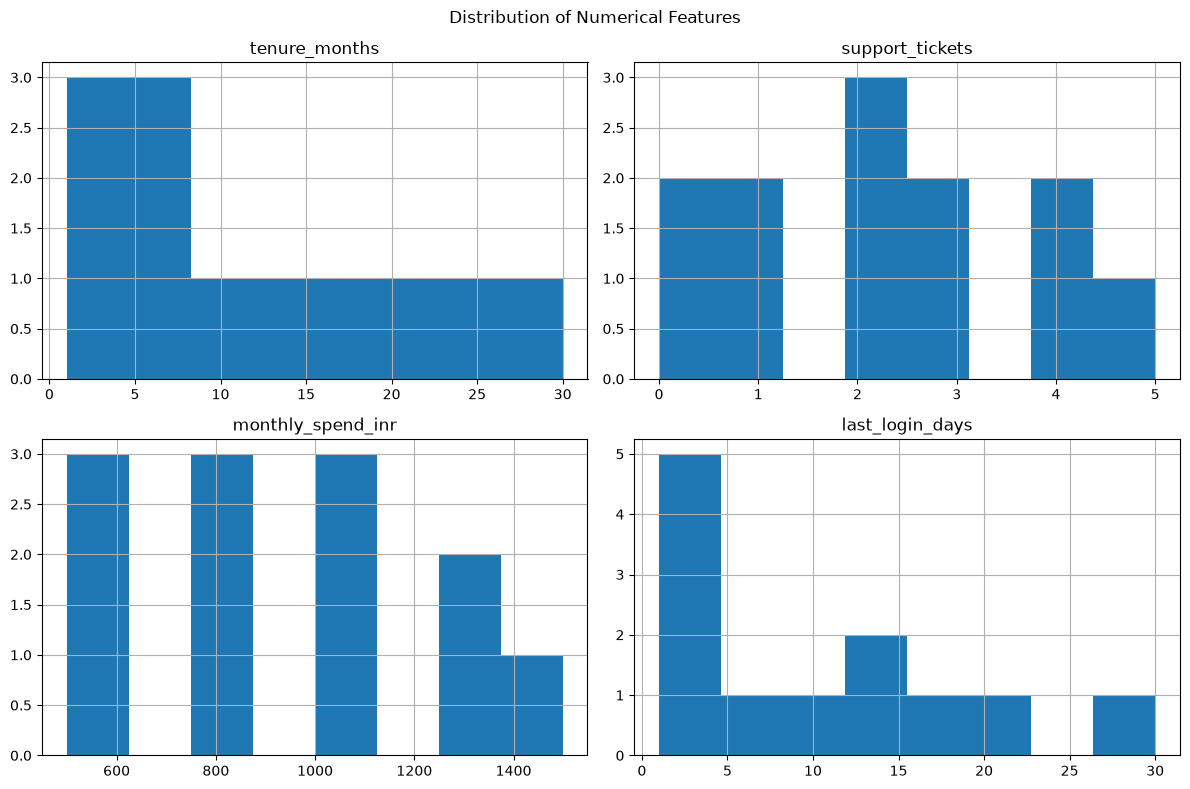

In [9]:
numerical_columns = [
    "tenure_months",
    "support_tickets",
    "monthly_spend_inr",
    "last_login_days"
]

df[numerical_columns].hist(
    figsize=(12, 8),
    bins=8
)

plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.show()

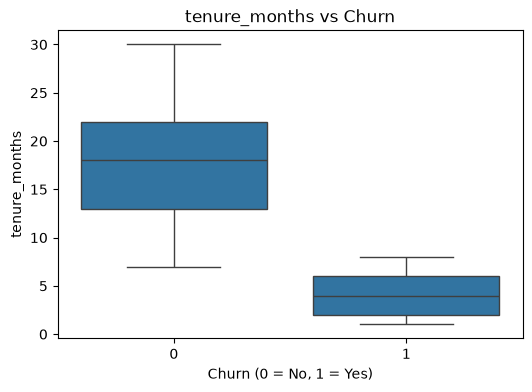

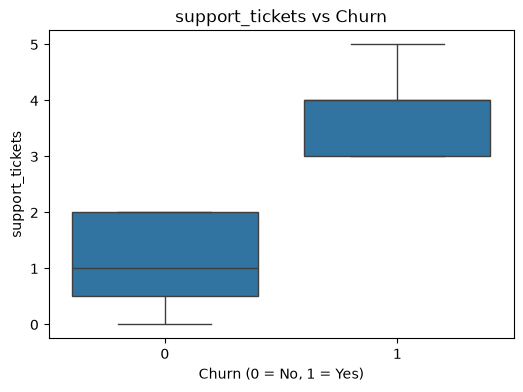

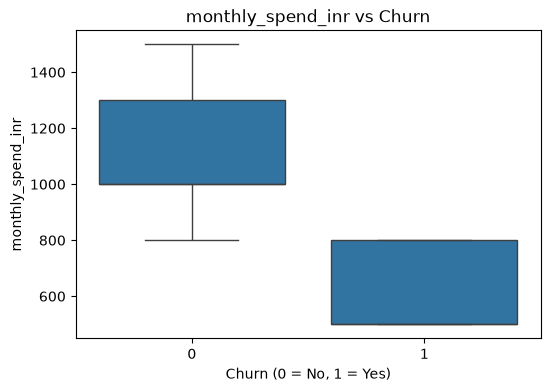

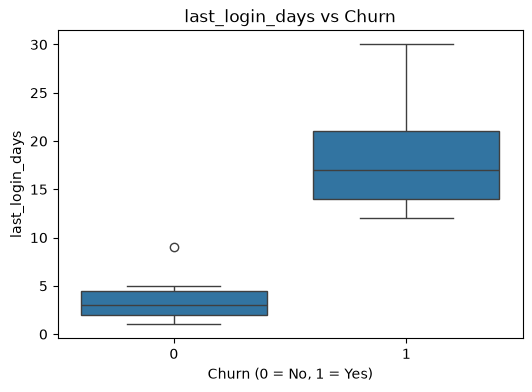

In [10]:
for column in numerical_columns:
    
    plt.figure(figsize=(6, 4))

    sns.boxplot(
        data=df,
        x="churned",
        y=column
    )

    plt.title(f"{column} vs Churn")
    plt.xlabel("Churn (0 = No, 1 = Yes)")

    plt.show()

churned,0,1
plan_type,,
Basic,0.0,100.0
Pro,100.0,0.0
Standard,100.0,0.0


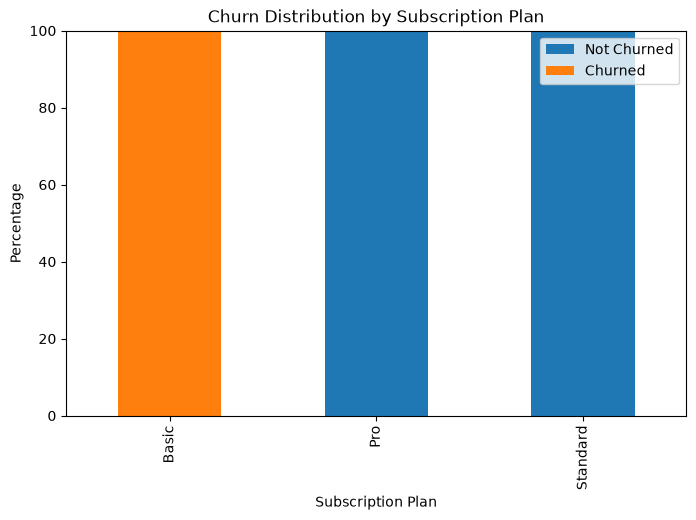

In [11]:
plan_churn = pd.crosstab(
    df["plan_type"],
    df["churned"],
    normalize="index"
) * 100

display(plan_churn)

plan_churn.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5)
)

plt.title("Churn Distribution by Subscription Plan")
plt.ylabel("Percentage")
plt.xlabel("Subscription Plan")
plt.legend(["Not Churned", "Churned"])

plt.show()